# Homework 1 — Linear algebra and data processing

Original joint coursework: **Raha Sajed (credited as Fatemeh Sajed) and Aylar Rahimzadeh**. Post-course corrections: **Raha Sajed (`raha-sajed`)**.

This notebook follows [the assignment](AI4032_HW1.pdf). Linear algebra is corrected below; signal processing follows. The Iris section remains to be completed.

# 1. Linear algebra

## I-a. Matrix dimensions

The assignment gives $A\in\mathbb{R}^{2\times3}$ and $B\in\mathbb{R}^{4\times2}$.
A product $(m\times k)(k\times p)$ is defined only when its inner dimensions agree; its shape is $m\times p$. A transpose swaps rows and columns.

| Expression | Dimension check | Answer |
| --- | --- | --- |
| $BA$ | $(4\times2)(2\times3)$ | Defined: $4\times3$ |
| $B^T$ | Transpose of $4\times2$ | $2\times4$ |
| $B^TA$ | $(2\times4)(2\times3)$; $4\ne2$ | Undefined |
| $A^TB$ | $(3\times2)(4\times2)$; $2\ne4$ | Undefined |

**Correction:** reshaping a matrix to make a product run changes the matrix and the problem. The undefined products must remain undefined.

## I-b. Compute the defined expressions

For $i=1,\ldots,4$ and $j=1,\ldots,3$,
$$(BA)_{ij}=b_{i1}a_{1j}+b_{i2}a_{2j}.$$

$$BA=\begin{bmatrix}
b_{11}a_{11}+b_{12}a_{21}&b_{11}a_{12}+b_{12}a_{22}&b_{11}a_{13}+b_{12}a_{23}\\
b_{21}a_{11}+b_{22}a_{21}&b_{21}a_{12}+b_{22}a_{22}&b_{21}a_{13}+b_{22}a_{23}\\
b_{31}a_{11}+b_{32}a_{21}&b_{31}a_{12}+b_{32}a_{22}&b_{31}a_{13}+b_{32}a_{23}\\
b_{41}a_{11}+b_{42}a_{21}&b_{41}a_{12}+b_{42}a_{22}&b_{41}a_{13}+b_{42}a_{23}
\end{bmatrix}.$$

$$B^T=\begin{bmatrix}b_{11}&b_{21}&b_{31}&b_{41}\\b_{12}&b_{22}&b_{32}&b_{42}\end{bmatrix}.$$

There is no value to calculate for $B^TA$ or $A^TB$ with the given matrices. The numerical example below uses the same illustrative values as the original report; the symbolic answer above applies to arbitrary entries.

In [1]:
import numpy as np

A = np.array([[1, 2, 3], [4, 5, 6]])
B = np.array([[1, 2], [3, 1], [4, 5], [6, 7]])
BA = B @ A
BT = B.T
np.testing.assert_array_equal(BA, [[9, 12, 15], [7, 11, 15], [24, 33, 42], [34, 47, 60]])
np.testing.assert_array_equal(BT, [[1, 3, 4, 6], [2, 1, 5, 7]])
assert BA.shape == (4, 3) and BT.shape == (2, 4)
print("BA =\n", BA)
print("B transpose =\n", BT)
for name, left, right in [("B.T @ A", B.T, A), ("A.T @ B", A.T, B)]:
    try:
        left @ right
    except ValueError:
        print(f"{name}: undefined ({left.shape[1]} != {right.shape[0]})")
    else:
        raise AssertionError(f"{name} should be undefined")

BA =
 [[ 9 12 15]
 [ 7 11 15]
 [24 33 42]
 [34 47 60]]
B transpose =
 [[1 3 4 6]
 [2 1 5 7]]
B.T @ A: undefined (4 != 2)
A.T @ B: undefined (2 != 4)


## II-a. Row-vector and matrix predictions

A sample $x^{(i)}=[x_1^{(i)}\;x_2^{(i)}]$ has shape $1\times2$, and
$\theta=[\theta_1\;\theta_2]^T$ has shape $2\times1$. Therefore
$$x^{(i)}\theta=x_1^{(i)}\theta_1+x_2^{(i)}\theta_2\in\mathbb{R}^{1\times1}.$$

Stacking $n$ samples gives $X\in\mathbb{R}^{n\times2}$ and
$$X\theta=\begin{bmatrix}x_1^{(1)}\theta_1+x_2^{(1)}\theta_2\\\vdots\\x_1^{(n)}\theta_1+x_2^{(n)}\theta_2\end{bmatrix}\in\mathbb{R}^{n\times1}.$$

In NumPy, `X[i:i+1]` keeps a sample as a row matrix; `X[i]` produces a one-dimensional array. Column-shaped targets also prevent unintended broadcasting.

In [2]:
X = np.array([[1., 1.], [1., 2.], [1., 3.]])
theta = np.array([[0.5], [1.5]])
y = np.array([[2.], [4.], [6.]])
x_i = X[0:1]
assert x_i.shape == (1, 2) and theta.shape == (2, 1)
assert (x_i @ theta).shape == (1, 1)
assert (X @ theta).shape == (3, 1)
print("One sample prediction:", x_i @ theta, "shape:", (x_i @ theta).shape)
print("All predictions:\n", X @ theta, "shape:", (X @ theta).shape)

One sample prediction: [[2.]] shape: (1, 1)
All predictions:
 [[2. ]
 [3.5]
 [5. ]] shape: (3, 1)


## II-b. Vector form of the loss and its gradient

Let $y\in\mathbb{R}^{n\times1}$ and $r=X\theta-y$. The assignment uses the **sum** of squared errors:
$$J(\theta)=\sum_{i=1}^{n}(x^{(i)}\theta-y^{(i)})^2=r^Tr=(X\theta-y)^T(X\theta-y).$$
This is a scalar ($1\times1$). Expanding it gives
$$J=\theta^TX^TX\theta-2\theta^TX^Ty+y^Ty.$$
Since $X^TX$ is symmetric and $X,y$ do not depend on $\theta$,
$$\boxed{\nabla_\theta J=2X^TX\theta-2X^Ty=2X^T(X\theta-y)}\in\mathbb{R}^{2\times1}.$$

Equivalently, for $j\in\{1,2\}$,
$$\frac{\partial J}{\partial\theta_j}=2\sum_{i=1}^{n}x_j^{(i)}\bigl(x^{(i)}\theta-y^{(i)}\bigr).$$

**Correction:** the gradient must be evaluated, not left as an unevaluated derivative. There is no $1/n$ in this assignment's loss. Using MSE instead would divide this gradient by $n$; using $J/(2n)$ would give $X^Tr/n$.

In [3]:
def squared_error_and_gradient(X, theta, y):
    """Sum of squared errors; use explicit column vectors to avoid broadcasting."""
    X, theta, y = (np.asarray(value, dtype=float) for value in (X, theta, y))
    if X.ndim != 2 or theta.shape != (X.shape[1], 1) or y.shape != (X.shape[0], 1):
        raise ValueError("Expected X: (n, p), theta: (p, 1), y: (n, 1)")
    residual = X @ theta - y
    return float((residual.T @ residual).item()), 2 * X.T @ residual

J, gradient = squared_error_and_gradient(X, theta, y)
np.testing.assert_allclose(J, 1.25)
np.testing.assert_allclose(gradient, [[-3.], [-8.]])
np.testing.assert_allclose(J, sum(float((row @ theta).item() - target.item()) ** 2 for row, target in zip(X, y)))
print("J =", J)
print("Gradient =\n", gradient, "shape:", gradient.shape)

J = 1.25
Gradient =
 [[-3.]
 [-8.]] shape: (2, 1)


## Numerical verification

A central finite-difference approximation checks each partial derivative independently of the matrix-gradient formula. We test several data sizes and parameter values, plus a malformed target shape that would otherwise broadcast silently.

In [4]:
rng = np.random.default_rng(42)
max_absolute_error = 0.0
for n in (1, 3, 10):
    X_check = rng.normal(size=(n, 2))
    theta_check = rng.normal(size=(2, 1))
    y_check = rng.normal(size=(n, 1))
    loss, analytic = squared_error_and_gradient(X_check, theta_check, y_check)
    numeric = np.zeros_like(theta_check)
    epsilon = 1e-6
    for j in range(2):
        step = np.zeros_like(theta_check)
        step[j, 0] = epsilon
        plus, _ = squared_error_and_gradient(X_check, theta_check + step, y_check)
        minus, _ = squared_error_and_gradient(X_check, theta_check - step, y_check)
        numeric[j, 0] = (plus - minus) / (2 * epsilon)
    np.testing.assert_allclose(analytic, numeric, rtol=1e-6, atol=1e-6)
    max_absolute_error = max(max_absolute_error, float(np.max(np.abs(analytic - numeric))))
try:
    squared_error_and_gradient(X, theta, y.ravel())
except ValueError:
    pass
else:
    raise AssertionError("A one-dimensional target must be rejected")
print("All dimension, product, loss and gradient checks passed.")
print(f"Maximum absolute finite-difference error: {max_absolute_error:.2e}")

All dimension, product, loss and gradient checks passed.
Maximum absolute finite-difference error: 8.76e-10


# 2. Signal processing

The existing signal analysis follows below. This pass corrects linear algebra only; checking all signal requirements and completing Iris remain the next tasks.

## Signal feature extraction

This descriptive analysis reads the supplied MAT file, centers the signal, forms overlapping windows, and exports mean, population standard deviation and RMS. It makes no claim of fault classification accuracy. Physical sampling rate and amplitude units have not been independently established; frequency is reported in cycles/sample.

In [5]:
from pathlib import Path
import sys
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "HomeWork1" / "201.mat").is_file())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from IPython.display import display, Image
from HomeWork1.signal_analysis import run, HERE
summary = run(root / "HomeWork1" / "201.mat", HERE / "results")
{key: summary[key] for key in ["n_samples", "n_windows", "discarded_tail_samples", "frequency_unit", "all_features_finite"]}

{
  "n_samples": 245140,
  "n_windows": 3829,
  "discarded_tail_samples": 20,
  "all_features_finite": true
}


,start_sample,mean,std,rms
0,0,0.102716,0.151039,0.182657
1,64,0.102319,0.146235,0.178476
2,128,0.110667,0.113735,0.158691
3,192,0.108846,0.094127,0.143900
4,256,0.098798,0.191406,0.215400


,mean,std,rms
count,3829.000000,3829.000000,3829.000000
mean,0.000003,0.132965,0.144922
std,0.056368,0.044321,0.042641
min,-0.112371,0.046022,0.050821
25%,-0.048841,0.105378,0.118092
50%,-0.003307,0.126204,0.139423
75%,0.046954,0.152206,0.162835
max,0.125048,0.649391,0.649638


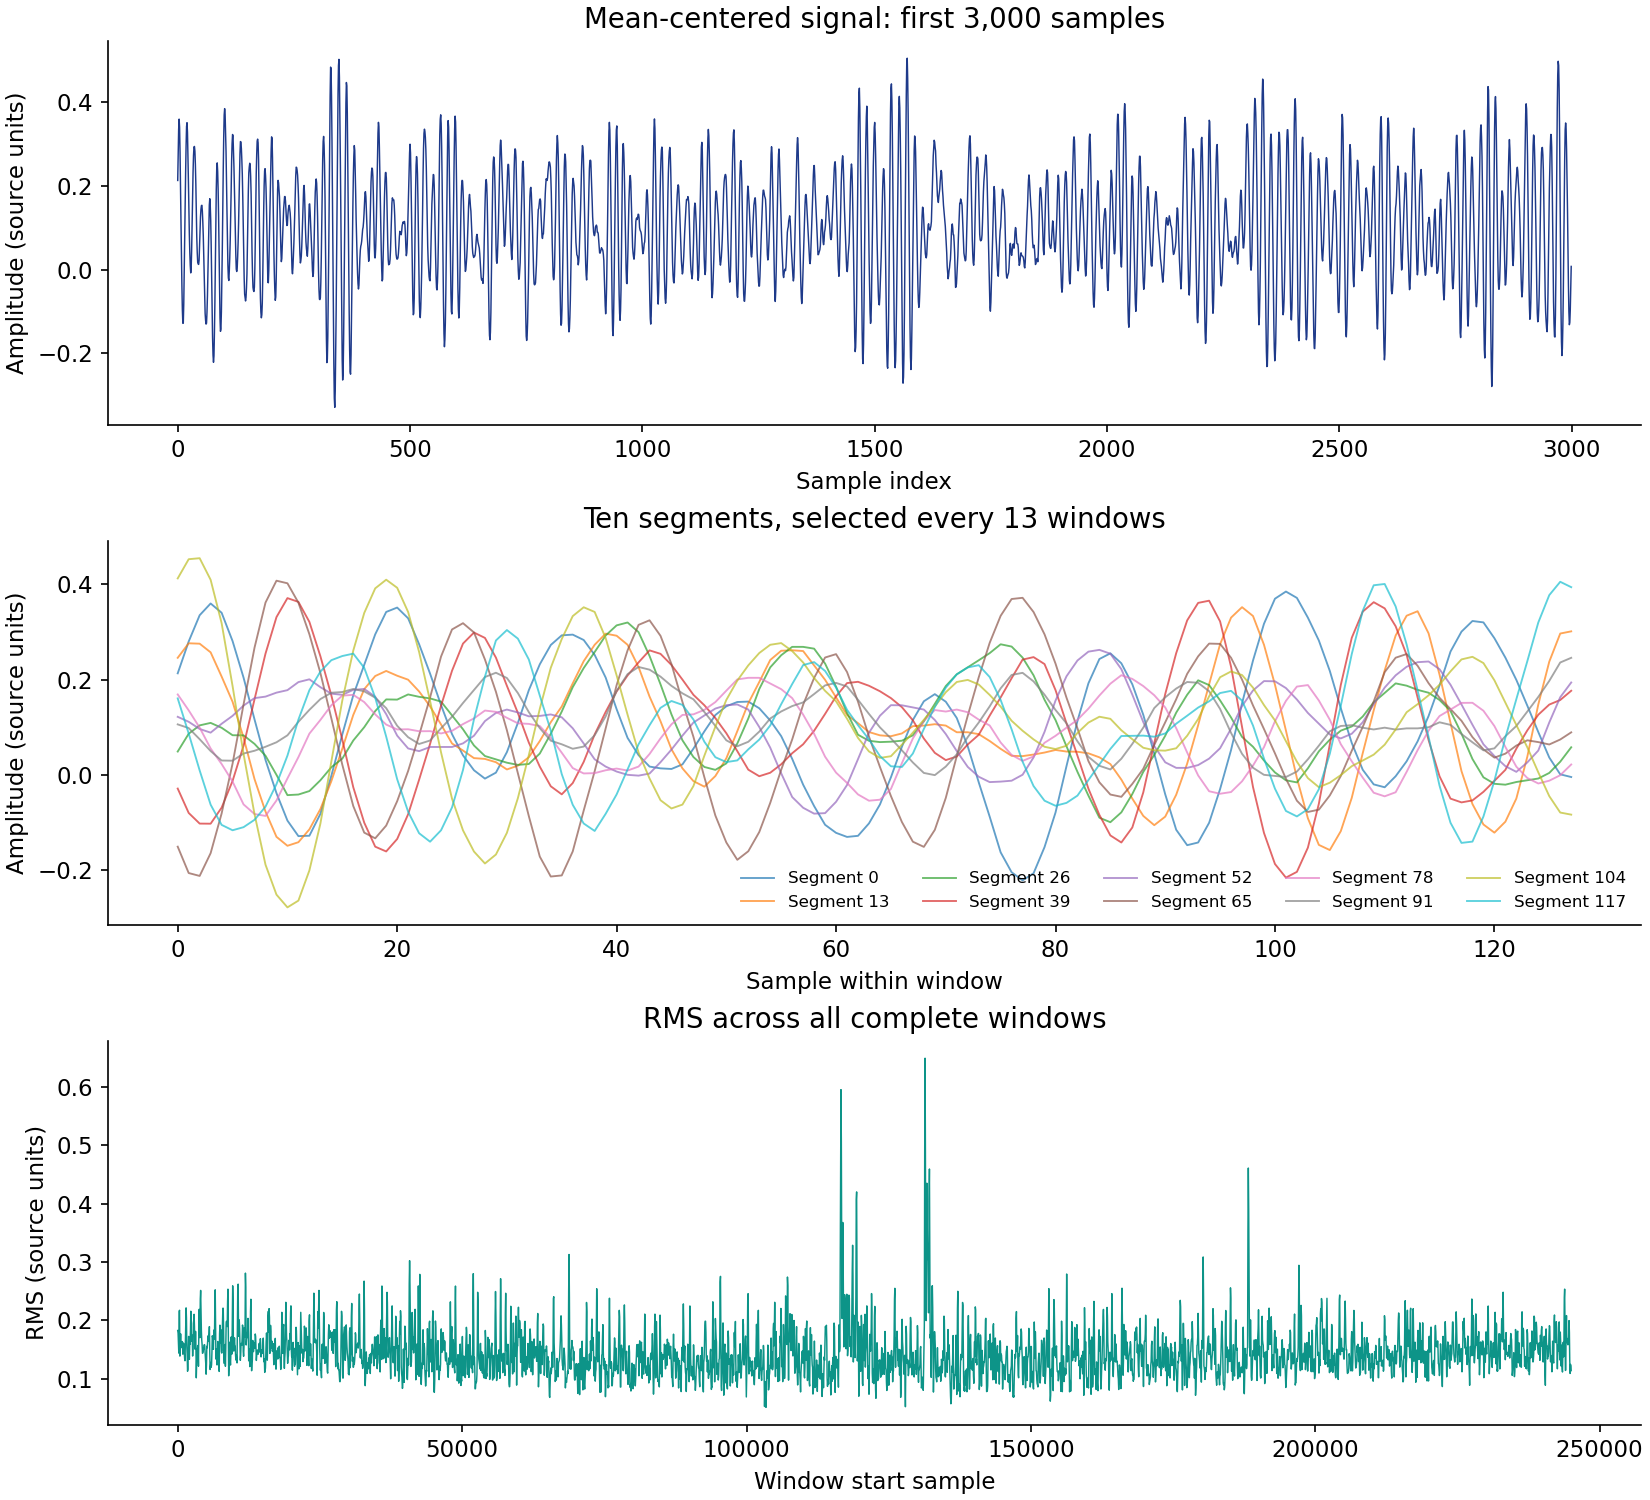

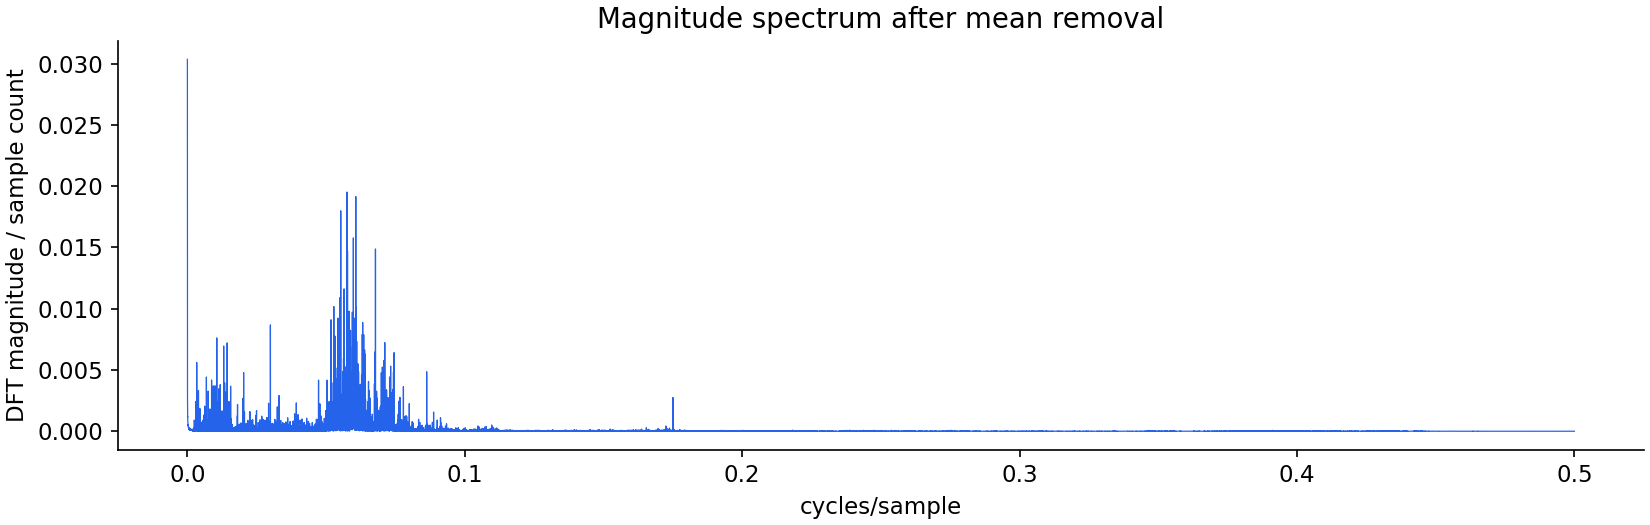

In [6]:
import pandas as pd
features = pd.read_csv(HERE / "results" / "segment_features.csv")
display(features.head())
display(features[["mean", "std", "rms"]].describe())
for filename in ["signal_analysis.png", "frequency_spectrum.png"]:
    display(Image(filename=str(HERE / "results" / filename)))

## Interpretation

There are 3,829 complete windows of 128 samples with 64 samples overlap. The final 20 samples are not included in a complete window. Whole-signal centering is used for descriptive analysis; a future predictive model would require a separate training/test protocol.

Linear algebra is completed above. The Iris exercise remains to be completed.